Attached you will find three tables:

erp_* denotes observation-based data (1996-2015) (climate model "driven" with observations)
epp_* denotes model-based data for the present period (1996-2015)


etp_* denotes model-based data for the future period (2081-2100). The scenario used is SSP3-7.0 (high emissions).
The variable names are as follows:

YY- Year it refers to

MM-Month
DD-Day
tas -  daily mean near surface air temperature (K)

tasmax - daily maximum temperature (K)

tasmin - daily minimum temperature (K)

hurs - daily mean relative humidity (%)

sfcwind - daily mean wind speed (m/s)


From the top we will have to conert the temperature (K) into C.
We will crate multiple new csv files where we will be adding new information, never deleting the previous one.

for future reference:

In [3]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import csv
import pandas as pd
import math

def celsius (df, coluna_K):
    for coluna in coluna_K:
        coluna_C=coluna.replace('Kelvin', 'Celsius')
        df[coluna_C]=df[coluna]-273.15 #converts Kelvin to Celsius
    return df

def wind_chill(T_air, M):
    """
    Calculate the wind chill index.
    T_air: Air temperature in ºC
    M: Wind speed in m/s
    Returns: Wind chill temperature in ºC
    """
    M0 = 4.8  # Km/h
    M = M * (3600 / 1000)  # Convert wind speed from m/s to km/h
    
    if M <= M0 and T_air < 10:
        return T_air  # No wind chill if wind is below threshold and temp is above 10ºC
    elif M <= M0 and T_air >= 10:
        return 'NA'  # Not applicable
    elif M > M0 and T_air >= 10:
        return 'NA'  # Not applicable
    elif M > M0 and T_air < 10:
        # Wind chill formula
        return 13.12 + 0.6215 * T_air - 11.37 * M ** 0.16 + 0.3965 * T_air * M ** 0.16
    
def heat_index(T,RH): #temperature in celsius and RH in percentage
    er=1.6 #KPa
    Tr=0.8841*T+(0.19)
    p=(0.0196*T)+0.9031
    es = 0.611 * math.exp(5423 * (1/273.15 - 1/(T + 273.15)))

    HI=Tr+(T-Tr)*((RH*es)/(100*er))**p
    return HI

def create_date_column(df):
    # Garantir que as colunas 'YY', 'MM', 'DD' são inteiros
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    
    # Criar uma coluna 'date' com o formato 'YYYY-MM-DD'
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    
    # Converter a coluna 'date' para datetime
    df['date'] = pd.to_datetime(df['date'])
    
    return df
    
csv_files = [
    r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100.csv']

temp_K=['tas', 'tasmax', 'tasmin']

for csv in csv_files:
    df=pd.read_csv(csv)#it reads the csv file (one of the ones that belongs to csv_files list)
    df=celsius (df, temp_K) #it says that the new data frame will have its temperatures changed to celsius
    df['wind_chill'] = df.apply(lambda row: wind_chill(row['tasmax'], row['sfcwind']), axis=1)
    df['heat_index'] = df.apply(lambda row: heat_index(row['tasmax'], row['hurs']), axis=1)
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    df['date'] = pd.to_datetime(df['date'])
    new_csv = csv.replace('.csv', '_WC+HI.csv')
    df.to_csv(new_csv, index=False)
    
# Carregar os arquivos CSV convertidos em DataFrames
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

# Exibir as primeiras linhas de cada DataFrame
print(df_erp.head())
print(df_epp.head())
print(df_etp.head())   

     YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996   1   1  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996   1   2  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996   1   3  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996   1   4  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996   1   5  13.673181  15.552148  12.153009  93.431549  3.309732   

   heat_index  wind_chill        date  
0   15.860420         NaN  1996-01-01  
1   15.095543         NaN  1996-01-02  
2   16.266594         NaN  1996-01-03  
3   16.081471         NaN  1996-01-04  
4   15.629709         NaN  1996-01-05  
     YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996   1   1  11.673853  13.337671   9.096735  97.802551  3.527462   
1  1996   1   2   9.494196  11.780542   7.350732  85.961823  2.174941   
2  1996   1   3  12.219019  14.014917  10.674646  95.754532  7.470380   
3  1996   1   4  14.409387  1

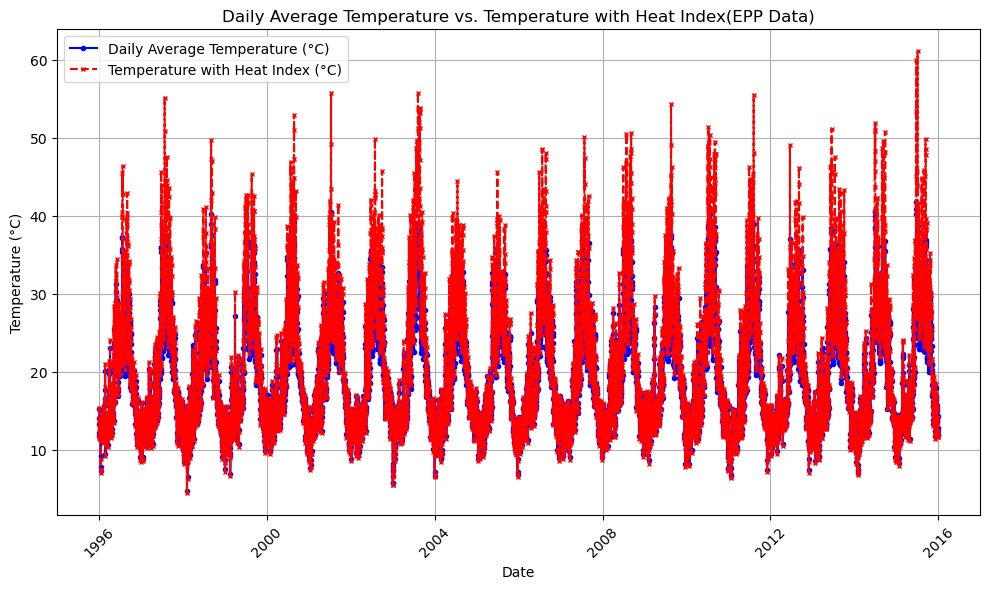

In [4]:
# Plotar o gráfico
#df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

plt.figure(figsize=(10, 6))
plt.plot(df_epp['date'], df_epp['tasmax'], label='Daily Average Temperature (°C)', color='blue', marker='o', markersize=3)
plt.plot(df_epp['date'], df_epp['heat_index'], label='Temperature with Heat Index (°C)', color='red', linestyle='--', marker='x', markersize=3)

# Adicionar título e rótulos aos eixos
plt.title(f'Daily Average Temperature vs. Temperature with Heat Index(EPP Data)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

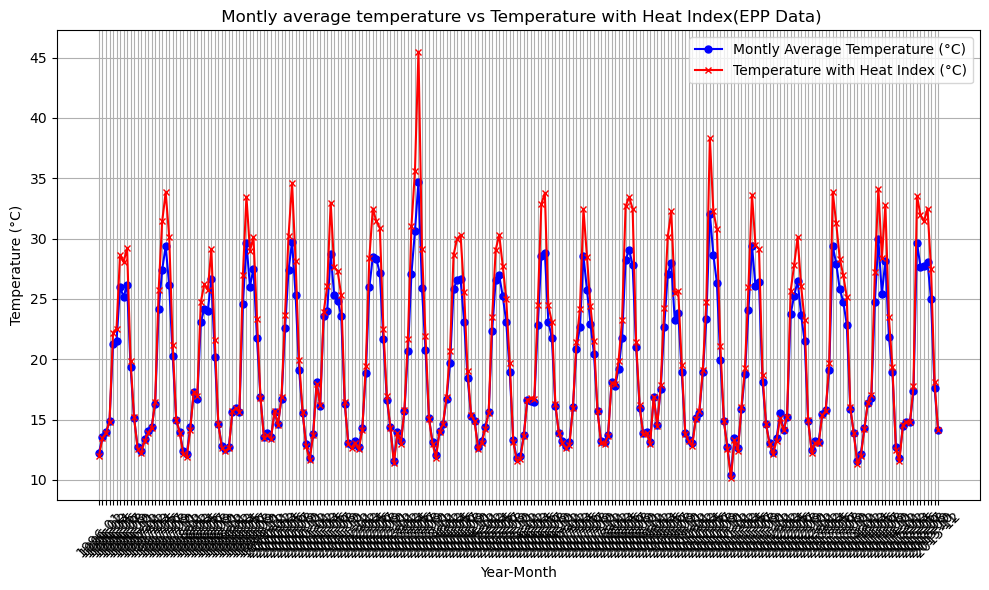

    year_month      YY    MM    DD        tas     tasmax     tasmin  \
0      1996-01  1996.0   1.0  16.0   9.034803  12.227777   6.381587   
1      1996-02  1996.0   2.0  15.0  10.374265  13.578927   7.756012   
2      1996-03  1996.0   3.0  16.0  11.308528  13.941093   8.693717   
3      1996-04  1996.0   4.0  15.5  11.552563  14.853699   8.752576   
4      1996-05  1996.0   5.0  16.0  15.953791  21.269036  11.094240   
..         ...     ...   ...   ...        ...        ...        ...   
235    2015-08  2015.0   8.0  16.0  21.808458  27.735926  17.210832   
236    2015-09  2015.0   9.0  15.5  21.625244  28.076619  15.927764   
237    2015-10  2015.0  10.0  16.0  19.395667  24.952902  14.654847   
238    2015-11  2015.0  11.0  15.5  14.638581  17.636691  11.840780   
239    2015-12  2015.0  12.0  16.0  12.107276  14.161076  10.079486   

          hurs   sfcwind  heat_index  wind_chill                date  
0    91.844722  3.012535   12.002539    7.337695 1996-01-16 00:00:00  
1    

In [5]:
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])
# Group by year and month
df_epp['year_month'] = df_epp['date'].dt.to_period('M')
df_monthly = df_epp.groupby('year_month').mean().reset_index()

# Convert 'year_month' to string for plotting
df_monthly['year_month'] = df_monthly['year_month'].astype(str)

# Plot the graph
plt.figure(figsize=(10, 6))
plt.plot(df_monthly['year_month'], df_monthly['tasmax'], 
         label='Montly Average Temperature (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_monthly['year_month'], df_monthly['heat_index'], 
         label='Temperature with Heat Index (°C)', color='red', marker='x', markersize=5)

# Add title and axis labels
plt.title(f' Montly average temperature vs Temperature with Heat Index(EPP Data)')
plt.xlabel('Year-Month')
plt.ylabel('Temperature (°C)')
plt.legend()

# Show grid and rotate x-axis labels
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print (df_monthly)

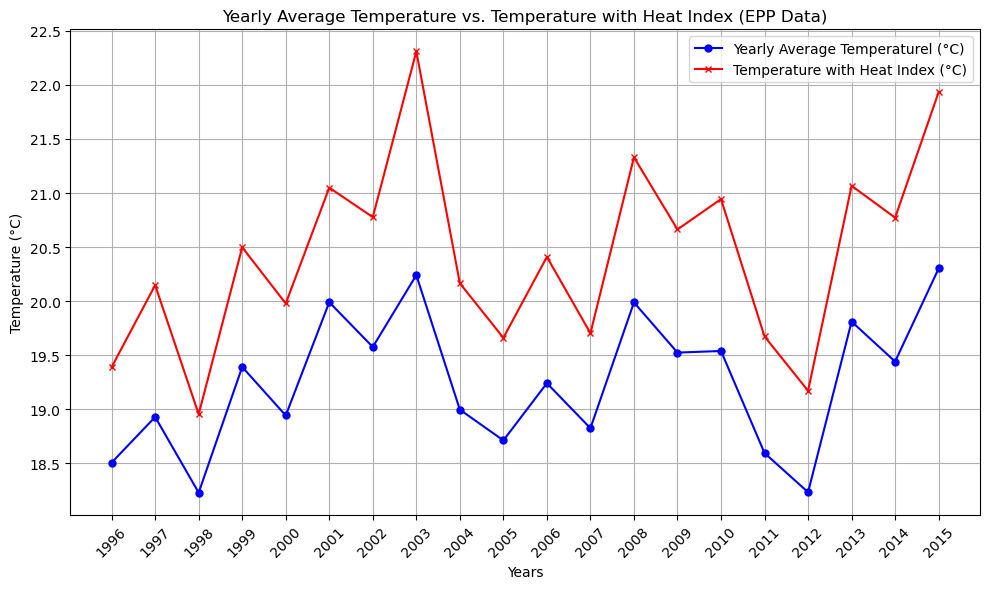

In [6]:
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])
# Calcular a média mensal da temperatura
# Vamos agrupar por ano e mês, e depois calcular a média de 'tas' e 'wind_chill'
df_epp['year'] = df_epp['date'].dt.to_period('Y')

# Calcular a média mensal para as colunas 'tas' (temperatura média) e 'wind_chill'
df_yearly = df_epp.groupby('year').mean().reset_index()
df_yearly['year'] = df_yearly['year'].astype(str)


# Plotar o gráfico para a temperatura média mensal e Wind Chill
plt.figure(figsize=(10, 6))
plt.plot(df_yearly['year'], df_yearly['tasmax'], 
         label='Yearly Average Temperaturel (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_yearly['year'], df_yearly['heat_index'], 
         label='Temperature with Heat Index (°C)', color='red', marker='x', markersize=5)
           
# Plotar Wind Chill, se existir
#if 'wind_chill' in df_monthly.columns:
 #   plt.plot(df_monthly['year_month'], df_monthly['wind_chill'], 
  #           label='Temperatura com Wind Chill Mensal (°C)', color='red', linestyle='--', marker='x', markersize=5)


# Adicionar título e rótulos aos eixos
plt.title(f'Yearly Average Temperature vs. Temperature with Heat Index (EPP Data)')
plt.xlabel('Years')
plt.ylabel('Temperature (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

Function to return the warmest months ()

And if i only want specific months (the warmest- june, july, augus, september)-6,7,8,9

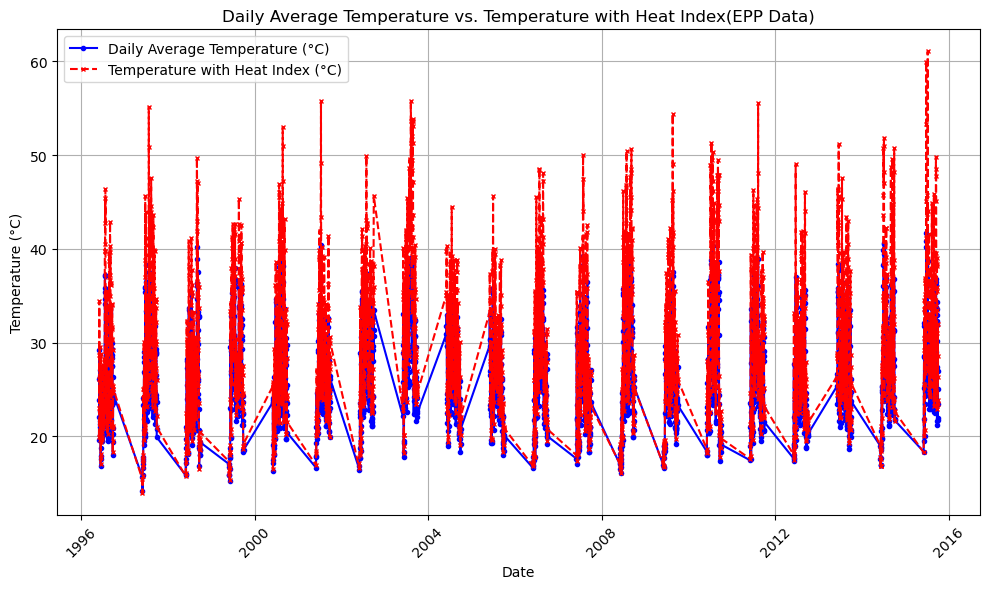

In [7]:
# Plotar o gráfico
#df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

summer_months = [6, 7, 8, 9]  # June to September
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)]


plt.figure(figsize=(10, 6))
plt.plot(df_summer['date'], df_summer['tasmax'], label='Daily Average Temperature (°C)', color='blue', marker='o', markersize=3)
plt.plot(df_summer['date'], df_summer['heat_index'], label='Temperature with Heat Index (°C)', color='red', linestyle='--', marker='x', markersize=3)

# Adicionar título e rótulos aos eixos
plt.title(f'Daily Average Temperature vs. Temperature with Heat Index(EPP Data)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

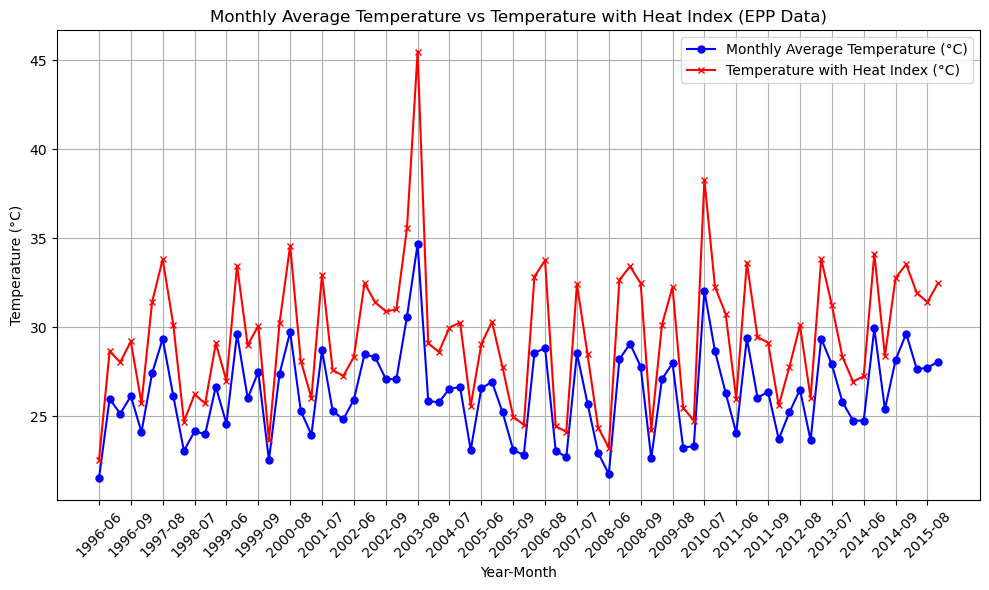

In [8]:

# Ensure 'date' column is in datetime format
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

# Filter for specific months (June, July, August, September)
summer_months = [6, 7, 8, 9]
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)].copy()

# Group by year and month
df_summer['year_month'] = df_summer['date'].dt.to_period('M')
df_monthly = df_summer.groupby('year_month').mean().reset_index()

# Convert 'year_month' to string for plotting
df_monthly['year_month'] = df_monthly['year_month'].astype(str)

# Check if required columns exist
if 'tasmax' not in df_monthly.columns or 'heat_index' not in df_monthly.columns:
    raise ValueError("Required columns 'tasmax' or 'heat_index' are missing in the dataset.")

# Plot the graph
plt.figure(figsize=(10, 6))
plt.plot(df_monthly['year_month'], df_monthly['tasmax'], 
         label='Monthly Average Temperature (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_monthly['year_month'], df_monthly['heat_index'], 
         label='Temperature with Heat Index (°C)', color='red', marker='x', markersize=5)

# Add title and axis labels
plt.title('Monthly Average Temperature vs Temperature with Heat Index (EPP Data)')
plt.xlabel('Year-Month')
plt.ylabel('Temperature (°C)')
plt.legend()

# Show grid and rotate x-axis labels
plt.grid(True)
plt.xticks(rotation=45)

# Optional: Adjust tick frequency (e.g., every 3 months)
plt.xticks(ticks=range(0, len(df_monthly['year_month']), 3), rotation=45)

plt.tight_layout()
plt.show()

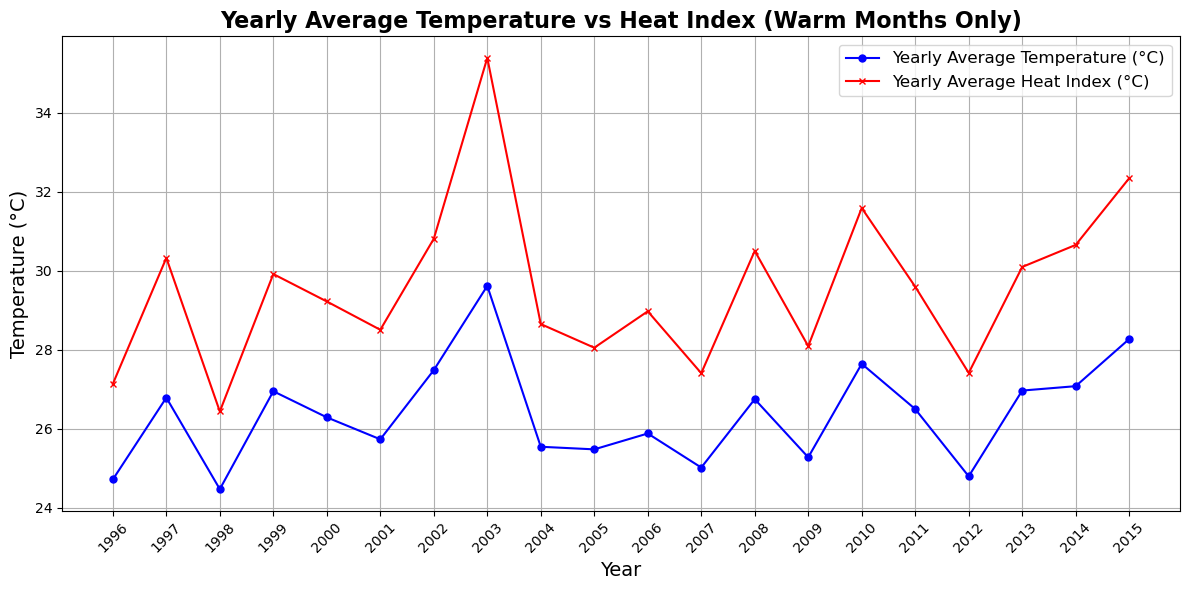

In [9]:
# Ensure 'date' column is in datetime format
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

# Filter for specific months (June, July, August, September)
summer_months = [6, 7, 8, 9]
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)].copy()

# Extract year and calculate yearly averages for the warm months
df_summer['year'] = df_summer['date'].dt.year
df_yearly = df_summer.groupby('year').mean().reset_index()

# Plot the graph
plt.figure(figsize=(12, 6))
plt.plot(df_yearly['year'], df_yearly['tasmax'], 
         label='Yearly Average Temperature (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_yearly['year'], df_yearly['heat_index'], 
         label='Yearly Average Heat Index (°C)', color='red', marker='x', markersize=5)

# Add title and axis labels
plt.title('Yearly Average Temperature vs Heat Index (Warm Months Only)', fontsize=16, weight='bold')
plt.xlabel('Year', fontsize=14)
plt.ylabel('Temperature (°C)', fontsize=14)
plt.legend(fontsize=12)

# Show grid and adjust x-axis ticks
plt.grid(True)
plt.xticks(df_yearly['year'], rotation=45, fontsize=10)  # Rotate for better readability

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

QUANDO SÃO 6 DIAS ACIMA DE 5 GRAUS

In [10]:

def analyze_heat_wave(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] + 5:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }


def filter_heat_wave_rows(csv_file):
    """
    Filter rows from the CSV file that correspond to detected heat waves.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    DataFrame: Rows corresponding to detected heat wave periods.
    """
    # Detect heat waves
    heat_wave_data = analyze_heat_wave(csv_file)

    # Read the original DataFrame
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Filter rows for each heat wave period
    heat_wave_rows = pd.DataFrame()
    for period in heat_wave_data['heat_waves']:
        start_date = period['start_date']
        end_date = period['end_date']
        heat_wave_rows = pd.concat([
            heat_wave_rows,
            df[(df['date'] >= start_date) & (df['date'] <= end_date)]
        ])

    return heat_wave_rows

# Example usage
csv_file = r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv'

# Detect and display heat wave periods
heat_wave_rows = filter_heat_wave_rows(csv_file)
print(heat_wave_rows)


        YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
143   1996   5  23  18.951868  25.873102  13.006403  77.530914  2.333347   
144   1996   5  24  21.978967  28.974908  15.165704  58.943470  2.538405   
145   1996   5  25  22.569543  30.240167  12.988367  51.290489  2.707301   
146   1996   5  26  23.210077  31.284937  14.154230  48.433857  3.083403   
147   1996   5  27  20.648126  27.856317  15.855371  62.857166  3.388750   
...    ...  ..  ..        ...        ...        ...        ...       ...   
7236  2015  10  24  21.673181  30.228418  12.769525  62.266964  2.075953   
7237  2015  10  25  22.290521  29.399896  15.148248  48.692650  2.319332   
7238  2015  10  26  20.443201  27.648401  13.869958  51.837154  1.407477   
7239  2015  10  27  18.087793  25.822504  11.592401  87.926620  0.410696   
7240  2015  10  28  19.261530  25.182916  14.744348  81.278046  1.034414   

      heat_index  wind_chill       date  
143    28.754851         NaN 1996-05-23  
144

In [11]:
analyze_heat_wave (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 115,
 'heat_waves': [{'start_date': Timestamp('1996-05-23 00:00:00'),
   'end_date': Timestamp('1996-05-30 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.747333526611326,
   'max_degree_above': 8.074859619140625,
   'min_degree_above': 5.00921630859375},
  {'start_date': Timestamp('1996-06-01 00:00:00'),
   'end_date': Timestamp('1996-06-08 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.546478271484382,
   'max_degree_above': 8.390960693359379,
   'min_degree_above': 5.015411376953182},
  {'start_date': Timestamp('1996-07-17 00:00:00'),
   'end_date': Timestamp('1996-07-26 00:00:00'),
   'duration': 10,
   'avg_degrees_above_threshold': 8.240066528320309,
   'max_degree_above': 11.251556396484375,
   'min_degree_above': 5.2731018066406286},
  {'start_date': Timestamp('1996-08-24 00:00:00'),
   'end_date': Timestamp('1996-09-08 00:00:00'),
   'duration': 16,
   'avg_degrees_above_threshold': 7.850875854492184,
   'max_degree_abo

QUANDO SÃO 6 DIAS ACIMA DE 8 GRAUS

In [12]:

def analyze_heat_wave(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] +8:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [13]:
analyze_heat_wave (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 10,
 'heat_waves': [{'start_date': Timestamp('1997-08-09 00:00:00'),
   'end_date': Timestamp('1997-08-17 00:00:00'),
   'duration': 9,
   'avg_degrees_above_threshold': 9.158338758680562,
   'max_degree_above': 10.791839599609375,
   'min_degree_above': 8.063537597656303},
  {'start_date': Timestamp('2002-06-20 00:00:00'),
   'end_date': Timestamp('2002-06-26 00:00:00'),
   'duration': 7,
   'avg_degrees_above_threshold': 9.117723737444189,
   'max_degree_above': 9.737640380859322,
   'min_degree_above': 8.175109863281246},
  {'start_date': Timestamp('2002-07-29 00:00:00'),
   'end_date': Timestamp('2002-08-03 00:00:00'),
   'duration': 6,
   'avg_degrees_above_threshold': 9.231836954752604,
   'max_degree_above': 10.393310546875,
   'min_degree_above': 8.013580322265625},
  {'start_date': Timestamp('2003-08-02 00:00:00'),
   'end_date': Timestamp('2003-08-09 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 9.255077362060547,
   'max_degree_above': 

QUANDO SÃO 6 DIAS ACIMA DE 10 GRAUS

In [14]:
def analyze_heat_wave(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] +10:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [15]:
analyze_heat_wave (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 1,
 'heat_waves': [{'start_date': Timestamp('2010-08-28 00:00:00'),
   'end_date': Timestamp('2010-09-05 00:00:00'),
   'duration': 9,
   'avg_degrees_above_threshold': 11.01672024197048,
   'max_degree_above': 12.350219726562496,
   'min_degree_above': 10.34783935546875}]}

In [16]:
# Read the CSV file
csv_file = r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv'
df = pd.read_csv(csv_file)

# Convert 'date' column to datetime if it's not already
df['date'] = pd.to_datetime(df['date'])

# Define the start and end dates for the range
start_date = '2010-08-28'
end_date = '2010-09-05'

# Convert these strings to datetime objects
start_date = pd.to_datetime(start_date)
end_date = pd.to_datetime(end_date)

# Filter the DataFrame for rows where the date is within the range
filtered_rows = df[(df['date'] >= start_date) & (df['date'] <= end_date)]

# Print the filtered rows
print(filtered_rows)

        YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
5353  2010   8  28  23.627802  34.293085  13.273676  61.395214  1.700077   
5354  2010   8  29  24.225244  35.065424  14.194574  53.772911  0.676689   
5355  2010   8  30  24.130457  35.911035  12.696741  43.586071  1.789141   
5356  2010   8  31  26.239008  38.589227  15.117365  44.946899  1.759807   
5357  2010   9   1  26.363428  37.022668  16.845087  43.551949  1.363078   
5358  2010   9   2  25.725305  36.783533  16.434686  54.406876  1.764262   
5359  2010   9   3  24.689844  35.037683  16.250940  64.190445  1.533501   
5360  2010   9   4  25.924341  36.920465  15.972925  58.383018  2.000533   
5361  2010   9   5  26.770868  37.223657  17.023492  52.818962  0.997232   

      heat_index  wind_chill       date  
5353   43.118069         NaN 2010-08-28  
5354   42.537382         NaN 2010-08-29  
5355   41.008272         NaN 2010-08-30  
5356   47.882462         NaN 2010-08-31  
5357   43.398532         NaN 

NOW, LETS USE THE HEAT WAVE INDEX, DEFINED BY PORTUGAL, AND INSTEAD OF USING THE DIRECT TEMPERATURE, USE THE APPARENT TEMPERATURE

In [ ]:
def analyze_heat_wave(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] +10:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }